In [5]:
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Ellipse, Polygon, RegularPolygon, PathPatch, FancyArrowPatch
from shapes import draw_database
import numpy as np

nodes = {

    "Mission": ["mission",],
    "Context": ["leadership_vision","leadership_objectives","stakeholder_demands","stakeholder_questions","problem_statement",],
    "Problem Definition": ["stakeholders","related_agents","questions","requirements","timeline",],
    "Agent Properties": ["aor","assets","objectives","tasking",], # leave-unstaged
    "Assessment": ["overall_assessment","input_data", "criteria_and_weighting","logic","analysis","modeling_and_sim","outputs","recommendations",],
}

stage_style = {
    "Mission": {
        "fillcolor": "#878787",
        "shape": "pentagon",
    },
    "Context": {
        "fillcolor": "#ADD8E6",
        "shape": "box",
    },
    "Problem Definition": {
        "fillcolor": "#90EE90",
        "shape": "box",
    },
    "Agent Properties": {
        "fillcolor": "#D1FFCA",
        "shape": "box",
    },
    "Assessment": {
        "fillcolor": "#F08080",
        "shape": "box",
    },
}

categories = {

    "Drivers": ["mission","leadership_vision","leadership_objectives","stakeholder_demands","stakeholder_questions","problem_statement",],
    "Demands": ["stakeholders","related_agents","questions","requirements","timeline",],
    "Agent_Attributes": ["aor","assets","objectives","tasking",],
    "Assessment": ["overall_assessment","criteria_and_weighting","input_data","logic","analysis","modeling_and_sim",],
    "Deliverables": ["outputs","recommendations",],
}

G = nx.DiGraph()
for stage, items in nodes.items():
    for item in items:
        category = [c for c, vals in categories.items()if item in vals][0]
        G.add_node(item,stage=stage,category=category,**stage_style[stage])

G.nodes()['input_data']['shape'] = 'database'
relations = {
    "context_flow": [
        ("mission", "leadership_vision"), ("mission", "leadership_objectives"), ("leadership_vision", "leadership_objectives"), ("leadership_objectives", "leadership_vision"),
        ("leadership_vision", "stakeholder_demands"), ("leadership_vision", "stakeholder_questions"),("leadership_objectives", "stakeholder_demands"),("leadership_objectives", "stakeholder_questions"),
        ("stakeholder_demands", "stakeholder_questions"), ("stakeholder_questions","stakeholder_demands"), ("stakeholder_demands", "problem_statement"), ("stakeholder_questions","problem_statement"), 
    ],
    #"problem_definition": [("problem_statement", "stakeholders"),("problem_statement", "related_agents"),("problem_statement", "questions"),("problem_statement", "requirements"),("problem_statement", "timeline"),],
    #"agent_properties": [(agent, prop) for agent in ["stakeholders","related_agents",] for prop in nodes["Agent Properties"]],
    "problem_to_assessment": [(item, "overall_assessment")for item in nodes["Problem Definition"]],
    #"context_to_assessment": [(item, "overall_assessment")for item in nodes["Context"]],
    "assessment_structure": [("overall_assessment", item) for item in nodes["Assessment"] if item not in ["overall_assessment", "recommendations", "outputs"]],
    "assessment_outputs": [(item, "outputs") for item in ["input_data","logic","criteria_and_weighting","analysis","modeling_and_sim",]],
    "recommendations": [("outputs", "recommendations")],
}

for relation, edge_list in relations.items():
    for u, v in edge_list:
        G.add_edge(u,v,relation=relation)




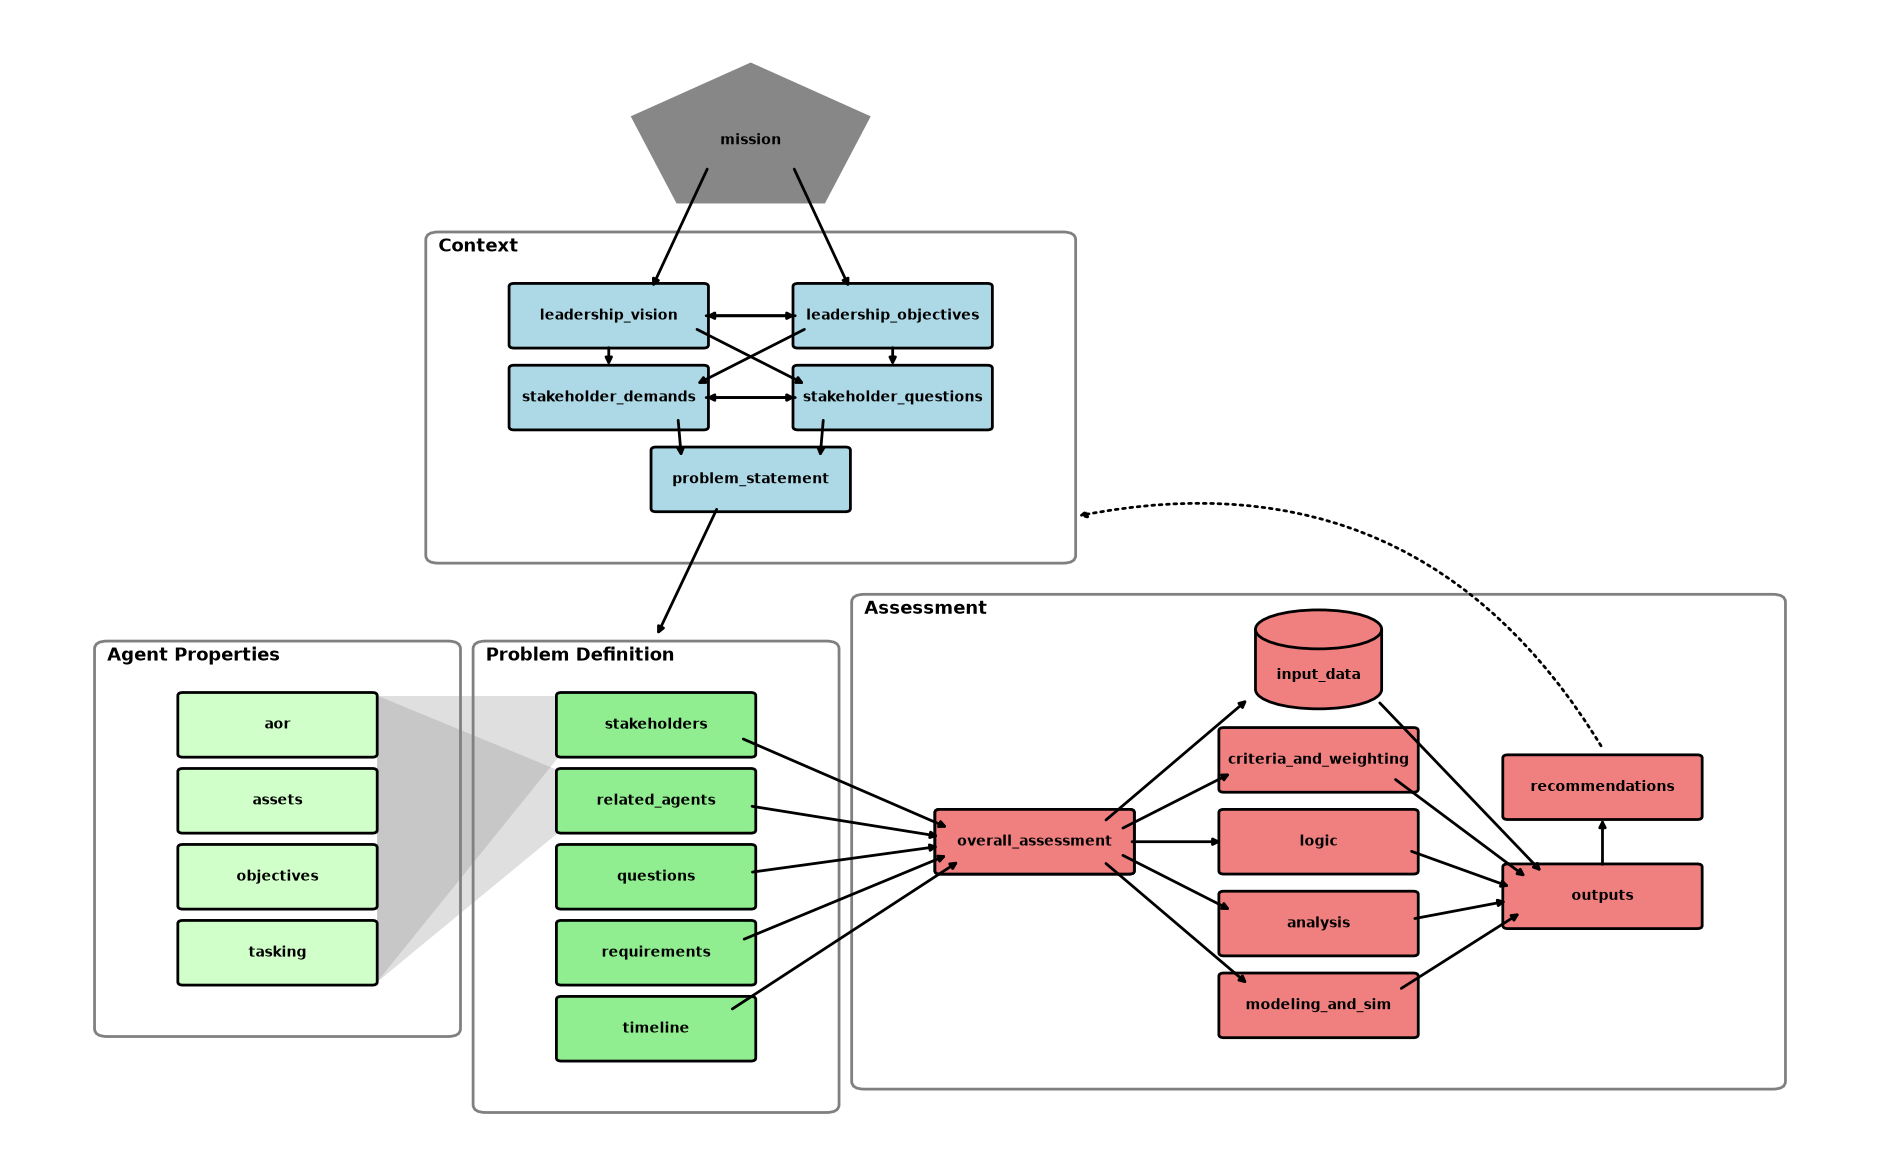

In [6]:


SCALE = 1.5
NODE_WIDTH = 2 * SCALE
NODE_HEIGHT = 1 * SCALE

clusters = {
    "Mission": {
        "origin": (5*SCALE, 15*SCALE),
        "layout": "single",
    },
    "Context": {
        "origin": (5*SCALE, 12*SCALE),
        "layout": "context",
        "dx": 2.8*SCALE,
    },
    "Agent Properties": {
        "origin": (0*SCALE, 5*SCALE),
        "layout": "vertical",
        "dy": 1.3*SCALE,
    },
    "Problem Definition": {
        "origin": (4*SCALE, 5*SCALE),
        "layout": "vertical",
        "dy": 1.3*SCALE,
    },
    "Assessment": {
        "origin": (8*SCALE, 3*SCALE),
        "layout": "assessment",
        "dy": 1.3*SCALE,
    },
}

def build_positions(G, clusters):
    x_space = 1.5
    y_space = 1.4

    pos = {}
    for stage, cfg in clusters.items():
        members = [n for n, d in G.nodes(data=True) if d["stage"] == stage]
        x0, y0 = cfg["origin"]

        if cfg["layout"] == "single":
            pos[members[0]] = (x0, y0)

        elif cfg["layout"] == "horizontal":
            dx = cfg.get("dx", 2)
            for i, node in enumerate(members):
                pos[node] = (x0 + i*dx, y0)

        elif cfg["layout"] == "vertical":
            dy = cfg.get("dy", 1.5)
            for i, node in enumerate(members):
                pos[node] = (x0, y0 - i*dy)

        elif cfg["layout"] == "assessment":

            pos["overall_assessment"] = (x0,y0)
            children = ["input_data","criteria_and_weighting","logic","analysis","modeling_and_sim",]


            offsets = [
                (x_space*NODE_WIDTH,2*y_space*NODE_HEIGHT),
                (x_space*NODE_WIDTH,y_space*NODE_HEIGHT),
                (x_space*NODE_WIDTH,0*NODE_HEIGHT),
                (x_space*NODE_WIDTH,-1*y_space*NODE_HEIGHT),
                (x_space*NODE_WIDTH,-2*y_space*NODE_HEIGHT),
            ]

            for node,(dx,dy) in zip(children,offsets):
                pos[node]=(x0+dx,y0+dy)

            pos["outputs"] = (x0+2*NODE_WIDTH*x_space,y0-y_space)
            pos["recommendations"] = (x0+2*NODE_WIDTH*x_space,y0+y_space)

        elif cfg["layout"] == "context":
            pos["leadership_vision"] = (x0 - NODE_WIDTH*x_space/2, y0)
            pos["leadership_objectives"] = (x0 + NODE_WIDTH*x_space/2, y0)
            pos["stakeholder_demands"] = (x0 - NODE_WIDTH*x_space/2, y0-NODE_HEIGHT*y_space)
            pos["stakeholder_questions"] = (x0 + NODE_WIDTH*x_space/2, y0-NODE_HEIGHT*y_space)
            pos["problem_statement"] = (x0, y0-2*NODE_HEIGHT*y_space)

        else:
            raise ValueError(f"Unknown layout {cfg['layout']}")
        
    return pos


def draw_clusters(ax,G,pos,pad=0.8*SCALE):

    stages = {}
    bounds = {}
    for node,data in G.nodes(data=True):
        stages.setdefault(data["stage"],[]).append(node)

    for stage,nodes in stages.items():
        if stage == 'Mission': continue

        xs = [pos[n][0] for n in nodes]
        ys = [pos[n][1] for n in nodes]
        xmin = min(xs) - NODE_WIDTH/2 - pad
        xmax = max(xs) + NODE_WIDTH/2 + pad

        ymin = min(ys) - NODE_HEIGHT/2 - pad
        ymax = max(ys) + NODE_HEIGHT/2 + pad
        bounds[stage] = {"xmin": xmin,"xmax": xmax,"ymin": ymin,"ymax": ymax}

        rect = FancyBboxPatch(
            (xmin,ymin),
            xmax-xmin,
            ymax-ymin,
            boxstyle="round,pad=0.2",
            linewidth=2,
            edgecolor="gray",
            facecolor="none",
        )

        ax.add_patch(rect)
        ax.text(xmin,ymax-0.3,stage,ha="left",fontsize=13,weight="bold",)
    return bounds


def edge_point(x1,y1,x2,y2):
    dx=x2-x1
    dy=y2-y1
    angle=np.arctan2(dy,dx)
    return (x1 + np.cos(angle)*NODE_WIDTH/2,y1 + np.sin(angle)*NODE_HEIGHT/2)

def draw_edges(ax,G,pos):

    for u,v in G.edges():
        x1,y1 = pos[u]
        x2,y2 = pos[v]
        start = edge_point(x1,y1,x2,y2)
        end = edge_point(x2,y2,x1,y1)

        ax.annotate(
            "",xy=end,xytext=start,
            arrowprops=dict(arrowstyle="-|>",lw=2,color="black",),
            zorder=3,
        )


def draw_nodes(ax, G, pos):

    for node, data in G.nodes(data=True):
        text_shift=0
        x, y = pos[node]
        shape = data.get("shape")

        if shape.lower() == "pentagon":
            box = RegularPolygon((x,y),numVertices=5,radius=NODE_WIDTH/1.5,orientation=0,facecolor=data["fillcolor"]
                                 )
        elif shape.lower() in ['db', 'bd', 'database']:
            text_shift = 0.05
            draw_database(ax, x, y+0.5, NODE_WIDTH, NODE_HEIGHT*1,1, facecolor=data['fillcolor'], edgecolor='black', lw='2', zorder=2, ry=0.5)

        else:
            box = FancyBboxPatch(
                (x - NODE_WIDTH/2, y - NODE_HEIGHT/2),
                NODE_WIDTH,
                NODE_HEIGHT,
                boxstyle="round,pad=0.08",
                linewidth=2,
                edgecolor="black",
                facecolor=data["fillcolor"],
                zorder=1,
            )

        ax.add_patch(box)
        ax.text(x,y+text_shift*NODE_HEIGHT,node,ha="center",va="center",fontsize=10,fontweight="bold",zorder=3,)

def draw_cluster_edge(ax, pos, source, target_point):

    x1, y1 = pos[source]
    x2, y2 = target_point
    start = edge_point(x1, y1, x2, y2)
    # target is not a node, so just terminate at the point
    end = (x2, y2)

    ax.annotate(
        "",xy=end,xytext=start,
        arrowprops=dict(arrowstyle="-|>",lw=2,color="black",),
        zorder=4,
    )

def draw_fan(ax,source_nodes,target_nodes, pos,color="gray",alpha=0.25):
    """ Drawn to map a node to set of nodes"""
    t1, t2 = target_nodes[0], target_nodes[1]
    target_x = pos[t1][0]+NODE_WIDTH/1.9
    target_y_min = pos[t2][1]-NODE_HEIGHT/2
    target_y_max = pos[t1][1]+NODE_HEIGHT/2

    for node in source_nodes:
        x, y = pos[node]
        # source node right edge
        source_x = x - NODE_WIDTH/2
        # source vertical span
        source_top = y + NODE_HEIGHT/2
        source_bottom = y - NODE_HEIGHT/2
        points = [(source_x, source_bottom),(source_x, source_top),(target_x, target_y_max),(target_x,target_y_min),]
        fan = Polygon(points,closed=True,facecolor=color,edgecolor="none",alpha=alpha,zorder=0,)
        ax.add_patch(fan)

def draw_feedback_arrow(ax, start, end):

    ax.annotate(
        "",xy=end,xytext=start,
        arrowprops=dict(arrowstyle="-|>",linestyle=":",linewidth=2,
                        color="black",connectionstyle="arc3,rad=0.35"
                        ),
        zorder=5,
    )

pos = build_positions(G, clusters)
fig,ax = plt.subplots(figsize=(16*SCALE,10*SCALE))

bounds = draw_clusters(ax,G,pos)
draw_fan(ax,["stakeholders","related_agents",], ["aor", "tasking"],pos,)
draw_edges(ax,G,pos)

problem_def_target = (
    clusters["Problem Definition"]["origin"][0],
    clusters["Problem Definition"]["origin"][1] + 1.5*SCALE
)

draw_cluster_edge(ax,pos,"problem_statement",problem_def_target)
draw_nodes(ax,G,pos)

draw_feedback_arrow(ax, (pos['recommendations'][0], pos["recommendations"][1]+1),(bounds["Context"]["xmax"]+0.2,bounds["Context"]["ymin"]+1))



ax.relim()
ax.autoscale_view()
plt.axis('off')
plt.show()


In [4]:
for n, d in G.nodes(data=True):
    print(n, d)

mission {'stage': 'Mission', 'category': 'Drivers', 'fillcolor': '#878787', 'shape': 'pentagon'}
leadership_vision {'stage': 'Context', 'category': 'Drivers', 'fillcolor': '#ADD8E6', 'shape': 'box'}
leadership_objectives {'stage': 'Context', 'category': 'Drivers', 'fillcolor': '#ADD8E6', 'shape': 'box'}
stakeholder_demands {'stage': 'Context', 'category': 'Drivers', 'fillcolor': '#ADD8E6', 'shape': 'box'}
stakeholder_questions {'stage': 'Context', 'category': 'Drivers', 'fillcolor': '#ADD8E6', 'shape': 'box'}
problem_statement {'stage': 'Context', 'category': 'Drivers', 'fillcolor': '#ADD8E6', 'shape': 'box'}
stakeholders {'stage': 'Problem Definition', 'category': 'Demands', 'fillcolor': '#90EE90', 'shape': 'box'}
related_agents {'stage': 'Problem Definition', 'category': 'Demands', 'fillcolor': '#90EE90', 'shape': 'box'}
questions {'stage': 'Problem Definition', 'category': 'Demands', 'fillcolor': '#90EE90', 'shape': 'box'}
requirements {'stage': 'Problem Definition', 'category': 'De